

## How do mutations arise in a population? Is it:
### - **Branching Process**: where mutations happen independently
### - **Event-associacted mutation**: mutations happen according to an external 'pressure'
 



## SAMPLING FROM PROVIDED DISTRIBUTIONS
### Let us start by figuring out how to create randomness 
### We can use code to generate random numbers through built in functions

In [130]:
import numpy as np
import matplotlib.pyplot as plt
np.random.rand(1,10) #10 numbers b/w 0 and 1 

array([[0.25254314, 0.11767998, 0.47206805, 0.11282865, 0.50016183,
        0.33201191, 0.09369954, 0.76282594, 0.98746644, 0.14363104]])

### Generate an array of random numbers 

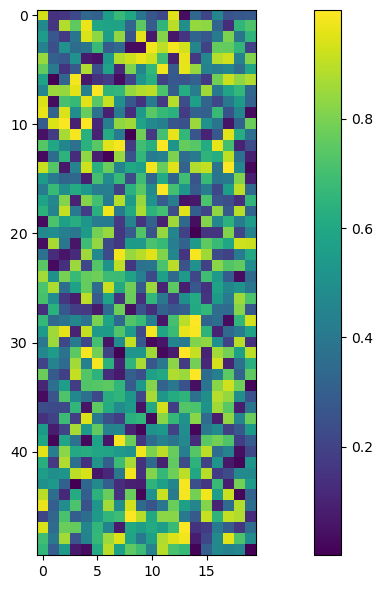

In [132]:
a = np.random.rand(50, 20)
plt.figure(figsize=(12,6))
plt.imshow(a, interpolation='none')
plt.colorbar()
plt.tight_layout()

## Challenge: Properties of random distributions
### - What is the mean and variance of `np.random.rand()`?
### - What shape does a large sample ($10^4$) histogram have?

## Answers:
### Mean = 0.5 as the values are uniformly spaced between 0 and 1

###  Variance = $<x^2> -<x>^2$


### $\text{Var}_x = \int_0^1 x^2 p(x) \,dx - \left( \int_0^1 x p(x) \,dx \right)^2$ 


### $= \frac{1}{3} x^3 \Big|_0^1 - \left( \frac{1}{2} x^2 \Big|_0^1 \right)^2$

### $= \frac{1}{3} - \left( \frac{1}{2} \right)^2$

### $= \frac{1}{12}$

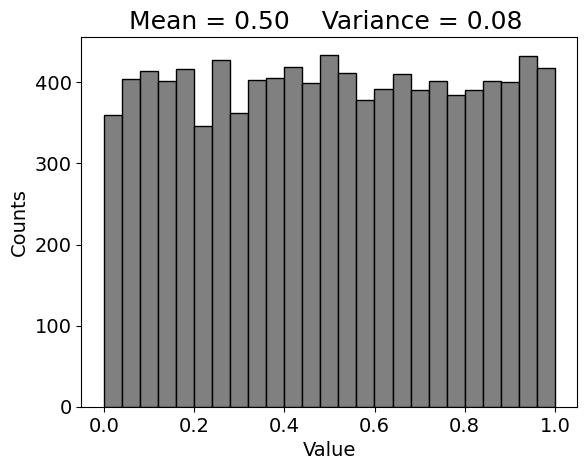

In [135]:
r = np.random.rand(10000)
#r = np.random.poisson(10, 10000)
#r = np.random.normal(100, 4, 10000)
m = np.mean(r)
v = np.var(r)
plt.hist(r, bins=25,color='grey', edgecolor='k');
plt.title(f"Mean = {m:.2f}    Variance = {v:.2f} ", fontsize=18);
plt.xlabel("Value", fontsize=14);
plt.ylabel("Counts", fontsize=14);
plt.xticks(fontsize=14);
plt.yticks(fontsize=14);

In [136]:
r = np.random.poisson(10000)
print(r)

10029


## Challenge: Random number generation

### Starting from `np.random.rand(1, 1000)`, obtain a random sampling, equally spaced in 
### the ranges:
- [0,5]
- [2, 7]
- [-5, 5]

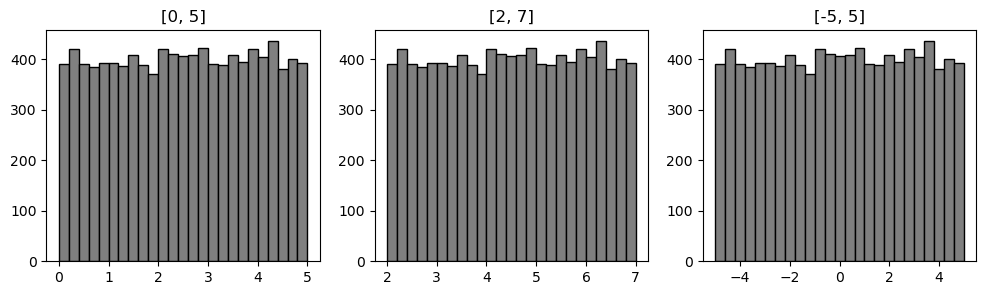

In [138]:
r = np.random.rand(10000)
r1 = r*5
r2 = r*5 + 2
r3 = r*10 - 5

plt.figure(figsize=(12, 3))
plt.subplot(131)
plt.hist(r1, bins=25, color='grey', edgecolor='k')
plt.title("[0, 5]")
plt.subplot(132)
plt.hist(r2, bins=25, color='grey', edgecolor='k')
plt.title("[2, 7]")
plt.subplot(133)
plt.hist(r3, bins=25, color='grey', edgecolor='k')
plt.title("[-5, 5]");


# Custom distributions

### A **cumulative distribution function** is the probability that the value is $x$ or lower. Note that y is a dummy variable used just for integration purposes

### $$P(x) = \int_{-\infty}^x p(y)dy $$

### The exponential distribution, linked to a constant rate $λ$

### $$p(x) = λ e^{-λ x}$$

### The exponential distribution models the waiting time between random events happening at a constant rate λ. The probability of waiting x time units is:

### $p(x) = λ e^{-λ x}$
### where λ is the average rate of events. It comes from the Poisson process, where events occur independently and continuously at a fixed rate.
### Example: Mutations, where mutations happen at a constant independent rate!




### The Cumulative Distribution Function (CDF) of the exponential distribution gives the probability that an event occurs within time t. It is derived by integrating the probability density function.
### $F(x) = P(X \leq x) = \int_0^x λ e^{-λ t} dt = 1 - e^{-λ x}$
### where F(x) gives the probablity that the event happens before or at time x 

# Link Between Exponential and Uniform Distributions
### Most programming languages (like Python, NumPy) have built-in functions to generate random numbers following the exponential distribution. However, it’s useful to understand how to generate these numbers manually.

### A key insight is that the exponential and uniform distributions are connected. In a uniform distribution (values between 0 and 1), half the values are below 0.5, but in an exponential distribution, the cutoff depends on λ. 

### Specifically, half the values satisfy:
### $1 - e^{-λ x} = 0.5$
### So we can set the above equation equal to the uniformly distributed random number $c_u$

### Conversion from uniformally distributed rand number ($c_u$) to exponentially distributed random number ($x_e$) : $x_e = -\frac{1}{λ} \log (1 - c_u)$

In [142]:
def rand2exp(prob_sample, my_lambda):
    # lambda is the rate of the Markov process
    # probsamp are uniformly randomly sampled numbers
    return -1/my_lambda*np.log(1-prob_sample)

my_lambda = 0.1
prob_sample = np.random.rand(10**4)
exp_sample = rand2exp(prob_sample, my_lambda)
print(prob_sample)
print(exp_sample)


[0.38528061 0.88076093 0.6001018  ... 0.89939094 0.67734554 0.88736784]
[ 4.86589388 21.26624832  9.16545265 ... 22.9651296  11.31173324
 21.83627975]


## Challenge problem: custom vs default exponential distributions

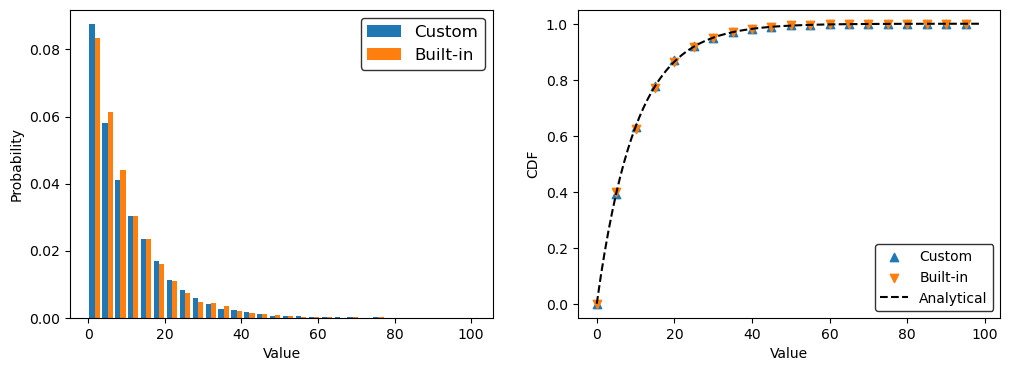

In [144]:
my_lambda = 0.1
n = 10**4
prob_sample = np.random.rand(n)
exp_sample = rand2exp(prob_sample, my_lambda)
python_sample = np.random.exponential(1/my_lambda, n)

plt.figure(figsize=(12, 4))
plt.subplot(121)
plt.hist([python_sample, exp_sample], density=True, bins=30, label=["Custom", "Built-in"])
plt.xlabel("Value")
plt.ylabel("Probability")
#plt.yscale("log")
plt.legend(fontsize=12, edgecolor='k');

from statsmodels.distributions.empirical_distribution import ECDF

x_vals = np.arange(0, 100, 5)
cdf_exp = ECDF(exp_sample)
cdf_built = ECDF(python_sample)

x_cont = np.arange(0, 100)
cdf_theo = 1- np.exp(-my_lambda*x_cont)

plt.subplot(122)
plt.scatter(x_vals, cdf_exp(x_vals), marker='^', label="Custom")
plt.scatter(x_vals, cdf_built(x_vals), marker='v', label="Built-in")
plt.plot(x_cont, cdf_theo, 'k--', label="Analytical")
plt.xlabel("Value")
plt.ylabel("CDF")
plt.legend(edgecolor='k');

In [145]:
from statsmodels.distributions.empirical_distribution import ECDF


## Binomial and Poisson distributions

## Binomial: $$P(k) = \binom{n}{k} p^k (1-p)^{n-k}$$
### eg; p = probability of mutation, n = number of cells, k = number of mutants , P(k) = probability that we see k mutants 

### However, if occurrences are rare and the number of samples, n, is large, then the binomial distribution converges to the Poisson distribution with shape parameter λ = np (this shape is the expected mean number of events in n trials, eg; p=0.1 in a sample size of 100 then λ = 10)
## Poisson:$$P(k) = \frac{λ^k e^{-λ}}{k!}$$

### At very large $n$, then Binomial $\approx$ Poisson, with $λ = n \cdot p$

### Challenge Problem: Comparing CDFs of Binomial and Poisson
### Over a range of samples `n=40, 100, 1000`

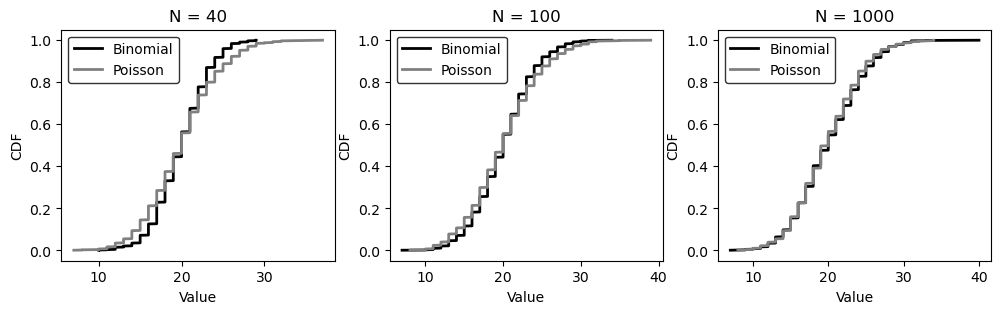

In [147]:

def cdf_binomial_poisson(my_lambda, n):
    p = my_lambda/n
    numsamps = 10**3
    
    # Binomial
    binosamps = np.random.binomial(n, p, numsamps)
    sortbino = np.sort(binosamps)
    cdfbino = np.arange(1, numsamps+1)/numsamps
    plt.plot(sortbino, cdfbino, color='k', linewidth=2, label="Binomial")
    
    # Poisson 
    poisson = np.random.poisson(n*p, numsamps)
    sortpois = np.sort(poisson)
    cdfpois = np.arange(1, numsamps+1)/numsamps
    plt.plot(sortpois, cdfpois, color='gray', linewidth=2, label="Poisson")
    
    plt.xlabel("Value")
    plt.ylabel("CDF")
    plt.legend(edgecolor='k')

plt.figure(figsize=(12, 3))
plt.subplot(131)
plt.title("N = 40")
cdf_binomial_poisson(20, 40)

#p = 20/n

plt.subplot(132)
plt.title("N = 100")
cdf_binomial_poisson(20, 100)

plt.subplot(133)
plt.title("N = 1000")
cdf_binomial_poisson(20, 1000)

Text(0, 0.5, 'CDF')

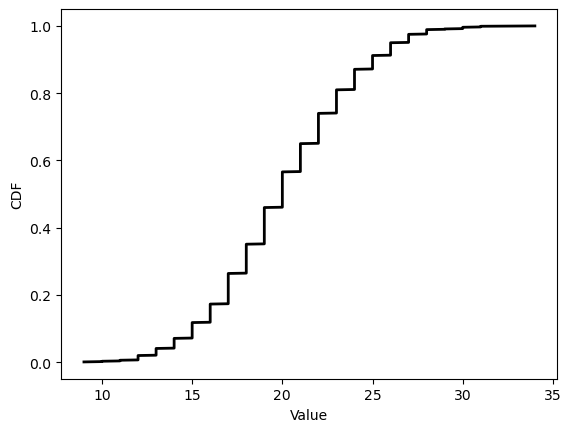

In [148]:

n=100
my_lambda = 20
p=my_lambda/n
numsamps=10**3
binosamps = np.random.binomial(n,p,numsamps)
sortbino = np.sort(binosamps)
cdfbino = np.arange(1,numsamps+1)/numsamps
plt.plot(sortbino,cdfbino,color='k',linewidth=2)
plt.xlabel("Value")
plt.ylabel("CDF")

# The start of dynamics
### Let's start with the case where **mutations are dependent on selection**. 
### Steps for a dynamic model
### 1. Population doubles in size
### 2. A fraction of the cells *changes*

## Step 1: Initialize an Array
## We start with an array of 5 cells, where one cell has a special property (e.g., mutation):

In [151]:
x = np.zeros(5)
print(f"At the start: {x}")
x[1] = 0.5
print(f"After change: {x}")

At the start: [0. 0. 0. 0. 0.]
After change: [0.  0.5 0.  0.  0. ]


## Step 2: Doubling the Population
## To simulate cell division, double the size of the array by stacking it with itself:

In [153]:
y = np.concatenate((x, x))
print(y)

[0.  0.5 0.  0.  0.  0.  0.5 0.  0.  0. ]


## Now, the new array y has twice as many cells as before. Notice that the 0.5 values appear in both the 2nd and 7th positions, meaning that the property (e.g., mutation) was inherited during division.

## If 0.5 represents a mutation, then after division, the number of mutant cells also doubled. To simulate new mutations, we can use random number generation (as described earlier) to decide which cells mutate in the new population.

## If we use 1 to represent a mutant cell and 0 for a wild-type cell, then during cell division, the number of mutant cells also doubles.



## Step 1: Initialize the Population
## Start with a small population containing one mutant (1) and one wild-type (0):

In [157]:
x = np.array([1, 0]) # 1 represents a mutant, 0 represents a wild-type

## Step 2: Simulate Cell Division
## Each time the population doubles, every cell (mutant or wild-type) gets copied:

In [159]:
x = np.array([1, 0])
for i in np.arange(4):  # Repeat for 4 generations
    x = np.concatenate((x, x), axis=None)
    print(x)

[1 0 1 0]
[1 0 1 0 1 0 1 0]
[1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0]
[1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0]


# Challenge Problem: A step towards bacterial growth
## Starting with `n=100` bacteria, and `p=0.1` of being a mutant:
## 1. Double the size of the population
## 2. Switch one element from 0->1 or 1->0.

In [161]:
# First, generate an array of 0-s and 1-s, using the np.random.choice function, in which ≈90% of them are 1-s
x = np.random.choice([1,0],size=(100,1),p=[0.9,0.1])

# Next, try and change a specific type, e.g., by changing it from 0 to 1 or 1 to 0.
ind = 20
x[ind]=1-x[ind]

#Double the array (stacks the two column vectors atop each other)
x.shape
x2 = np.concatenate((x,x),axis=0)
print(x2.shape)

#Double the array (produces two equal column vectors next to each other)
x.shape
x3 = np.concatenate((x,x),axis=1)
print(x3.shape)
#print(x3)

(200, 1)
(100, 2)


# Inferring parameters from data - or 90% of science

## While simulations and theory are cool, unbounded parameters can put a limit on how useful your theory or model can be. In order to get an estimate on the values we have to resort to **fitting**. In many cases you'll be fitting a model or curve to a set of data, or it can be fitting a distribution to find which 'shape' it has.


## The Poisson distribution is used to model the number of times an event occurs in a given period when events happen randomly at a fixed rate ( $λ $). The probability of observing \( k \) events is:

### $P(X = k) = \frac{λ^k e^{-λ}}{k!}$



## For example:
## The probability of 0 mutations is:

  ### P(0) = $e^{-λ}$

## The probability of 1 mutation is:

 ### P(1) = $λ e^{-λ}$

## The probability of 2 mutations is:

 ### P(2) = $\frac{λ^2}{2} e^{-λ}$



## Since the Poisson distribution models discrete events, the total probability must sum to 1:
### $\sum_{k=0}^{\infty} P(X = k | λ) = 1$


In [164]:
poissdata = np.genfromtxt('poissdata.csv', delimiter=',')
poissdata

array([3., 4., 2., 5., 2., 2., 5., 0., 5., 2., 4., 4., 4., 1., 4., 3., 3.,
       2., 3., 2., 2., 6., 3., 4., 4., 5., 2., 2., 5., 0., 1., 2., 2., 2.,
       4., 3., 3., 2., 4., 5., 2., 4., 6., 3., 5., 5., 1., 3., 1., 2., 2.,
       5., 4., 8., 4., 3., 5., 2., 6., 3., 3., 2., 3., 4., 4., 3., 2., 2.,
       3., 2., 6., 2., 2., 0., 2., 5., 4., 5., 4., 5., 3., 9., 3., 5., 2.,
       6., 3., 5., 1., 1., 2., 1., 4., 2., 5., 7., 4., 3., 4., 4.])

## One way to estimate $λ$ is by counting how often no mutations occur. The formula for estimating $λ$ from zero occurrences is:

### $ λ = -\log(P(X = 0)) $

## where $ P(X = 0) $ is the fraction of experiments that recorded zero mutations. We compute it as:

In [166]:
def lambda_estimator(x):
    numberofzeros = np.sum(x==0)
    probzero = numberofzeros/len(x)
    return -np.log(probzero)

lambda_est = lambda_estimator(poissdata)
print(lambda_est)

3.506557897319982


## Since Luria and Delbrück did not know the actual mutation rate, we must check how confident we are in our estimate. One way to do this is to simulate multiple trials and see if our estimated $λ$ falls within a 95\% confidence interval.

## Since the mean of a Poisson distribution is $λ$, we can simulate multiple datasets:


In [168]:
numsamps = 10**4
lambdadist = np.zeros(numsamps)

for j in range(numsamps):
    currdata = np.random.poisson(lambda_est, 100)
    lambdadist[j] = np.mean(currdata)

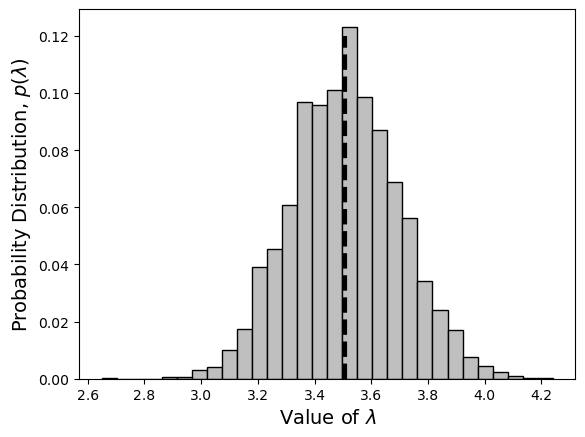

In [169]:
n, bin_edges = np.histogram(lambdadist, bins=30)
bin_probability = n / numsamps
bin_middles = (bin_edges[1:] + bin_edges[:-1]) / 2.
bin_width = bin_edges[1] - bin_edges[0]

plt.bar(bin_middles, bin_probability, width=bin_width, color=[0.75, 0.75, 0.75], edgecolor='k')
plt.plot([lambda_est, lambda_est], [0, 0.12], 'k--', linewidth=3)
plt.ylabel(r'Probability Distribution, $p(λ)$', fontsize=14)
plt.xlabel(r'Value of $λ$', fontsize=14)
plt.show()


## To determine if our estimate is reliable, we compute the range where 95\% of the estimates fall:




In [171]:
sortedlambdadist = np.sort(lambdadist)
lower025 = sortedlambdadist[int(0.025 * numsamps)]
upper975 = sortedlambdadist[int(0.975 * numsamps)]

## This gives us a confidence range $ [ λ_{\text{low}}, λ_{\text{high}} ] $, meaning we are 95\% sure the true $λ$ lies within this range.

## We can systematically test different values of λ to see how often our estimate falls within the 95% range:

In [174]:
lambdavec = np.arange(0.5 * lambda_est, 1.5 * lambda_est, 0.01)
lower025 = np.zeros(len(lambdavec))
upper975 = np.zeros(len(lambdavec))

for j in range(len(lambdavec)):
    currlambdaset = lambdavec[j]
    poissfitdist = np.zeros(numsamps)

    for k in range(numsamps):
        currdata = np.random.poisson(currlambdaset, 100)
        poissfitdist[k] = np.mean(currdata)

    sortedlambdadist = np.sort(poissfitdist)
    lower025[j] = sortedlambdadist[int(0.025 * numsamps)]
    upper975[j] = sortedlambdadist[int(0.975 * numsamps)]

## Challenge Problem: Estimating the confidence in rates

(1.25, 5.75)

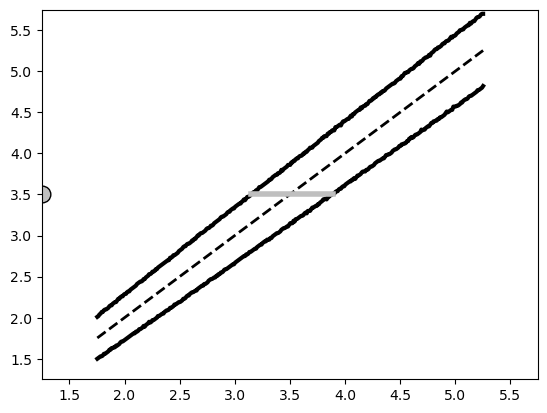

In [176]:
plt.plot(lambdavec,lower025,linewidth=3, color='k')
plt.plot(lambdavec,upper975, linewidth=3, color='k')
plt.plot(lambdavec,lambdavec,linewidth=2, linestyle='--', color='k')
tmpi=np.where(lower025 > lambda_est)[0]
llow=lambdavec[tmpi[0]]
tmpi=np.where(upper975 < lambda_est)[0]
lhigh=lambdavec[tmpi[-1]]
plt.plot([llow, lhigh],[lambda_est, lambda_est],
linewidth=4,color=[0.75,0.75,0.75])
plt.plot(1.25,lambda_est,'ko',markerfacecolor=[0.75,0.75,0.75],markersize=12)
plt.xlim([1.25, 5.75])
plt.ylim([1.25, 5.75])



## The plot shows how we determine confidence intervals for the estimated rate $ λ $. We do this by first sampling data multiple times and then sorting the estimates to find the range that contains $ 95\% $ of the values.

## To check if our estimate of $ λ = 3.51 $ is reasonable, we compare it with possible true values. If the true $ λ $ were $ 2.95 $, then $ 3.51 $ would be a possible upper limit. Similarly, if the true $ λ $ were $ 3.95 $, then $ 3.51 $ would be a possible lower limit.

## This helps define a confidence interval, showing the range of values that are consistent with our data. The plot includes a horizontal line at $ λ_{\text{est}} $ to illustrate this method.
